<a href="https://colab.research.google.com/github/Flor3ncia-Andr4d4/contar-con-datos-2026-sierrasdata/blob/main/El_Ni%C3%B1o_en_Argentina.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# El Niño en la Argentina (1950–2026): Variabilidad Térmica e Impacto Socio-Territorial
 **Categoría:** Historia visual

**Seudónimo:** SierrasData

 **Concurso:** Contar con Datos 2026

##  1. Autenticación y Configuración de Fuentes Oficiales (NASA Earthdata)

Para descargar los datasets satelitales primarios de Temperatura Superficial del Mar (TSM) desde los servidores de **NASA Earthdata**, se configura la autenticación remota mediante el archivo local `.netrc`.

Bloque 1: Configurar credenciales de la NASA

In [ ]:
import getpass
import os

# Configuración de credenciales de NASA Earthdata Login
# (Se utilizan variables seguras para resguardar la contraseña y el anonimato)
print(" Ingrese sus credenciales de NASA Earthdata Login:")
earthdata_user = input("Usuario NASA: ")
earthdata_pass = getpass.getpass("Contraseña NASA: ")

# Creación del archivo .netrc para descarga automatizada
netrc_content = f"machine urs.earthdata.nasa.gov login {earthdata_user} password {earthdata_pass}\n"
netrc_path = os.path.expanduser("~/.netrc")
with open(netrc_path, "w") as f:
  f.write(netrc_content)

os.chmod(netrc_path, 0o600)  # Permisos de lectura/escritura únicamente para el usuario
print(
    " Archivo .netrc configurado correctamente para descargas de NASA"
    " Earthdata."
)

 Ingrese sus credenciales de NASA Earthdata Login:
Usuario NASA: flor_andrada_26
Contraseña NASA: ··········
 Archivo .netrc configurado correctamente para descargas de NASA Earthdata.


Bloque 2: Instalar e importar librerías

In [ ]:

!pip install earthaccess -q > /dev/null 2>&1

import io
import urllib.request
import earthaccess
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

print("Librerías listas")

Librerías listas


Bloque 3: Graficar la Serie Histórica (1950 – Presente)



En esta sección se procesa la serie temporal histórica del **Índice Oceánico de El Niño (ONI)** provisto por la NOAA/CPC. Se analiza la variabilidad de la Temperatura Superficial del Mar (TSM) en la región Niño 3.4 desde 1950 hasta la actualidad, identificando los umbrales de categorización (*Niño Fuerte / Muy Fuerte $\ge +2,0\text{ }^\circ\text{C}$*) y destacando los cuatro eventos de magnitud histórica que impactaron a la Argentina: **1982–83**, **1997–98**, **2015–16** y el evento activo **2025–26**.
Categorización de Intensidad según Umbrales Oficiales de la NOAA (ONI)




FICHA DE TRAZABILIDAD Y AUDITORÍA DE FUENTES OFICIALES (JURADO)
• Institución Emisora: NOAA Climate Prediction Center (CPC) / NWS / NOAA PSL
• Dataset Oficial: Oceanic Niño Index (ONI) - ERSST.v5
• URL Directa (Producción): https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt

TABLA PROCESADA DE PICOS DESTACADOS (DETECCIÓN AUTOMÁTICA):
Etiqueta Trimestre  Anomalia
 1957-58       DJF      1.69
 1965-66       OND      1.82
 1972-73       OND      1.84
 1982-83       DJF      2.14
 1997-98       NDJ      2.37
 2009-10       NDJ      1.50
 2015-16       NDJ      2.59
 2023-24       NDJ      1.99
 2025-26       JAS      2.16

-------------------------------------------------------------------------------------


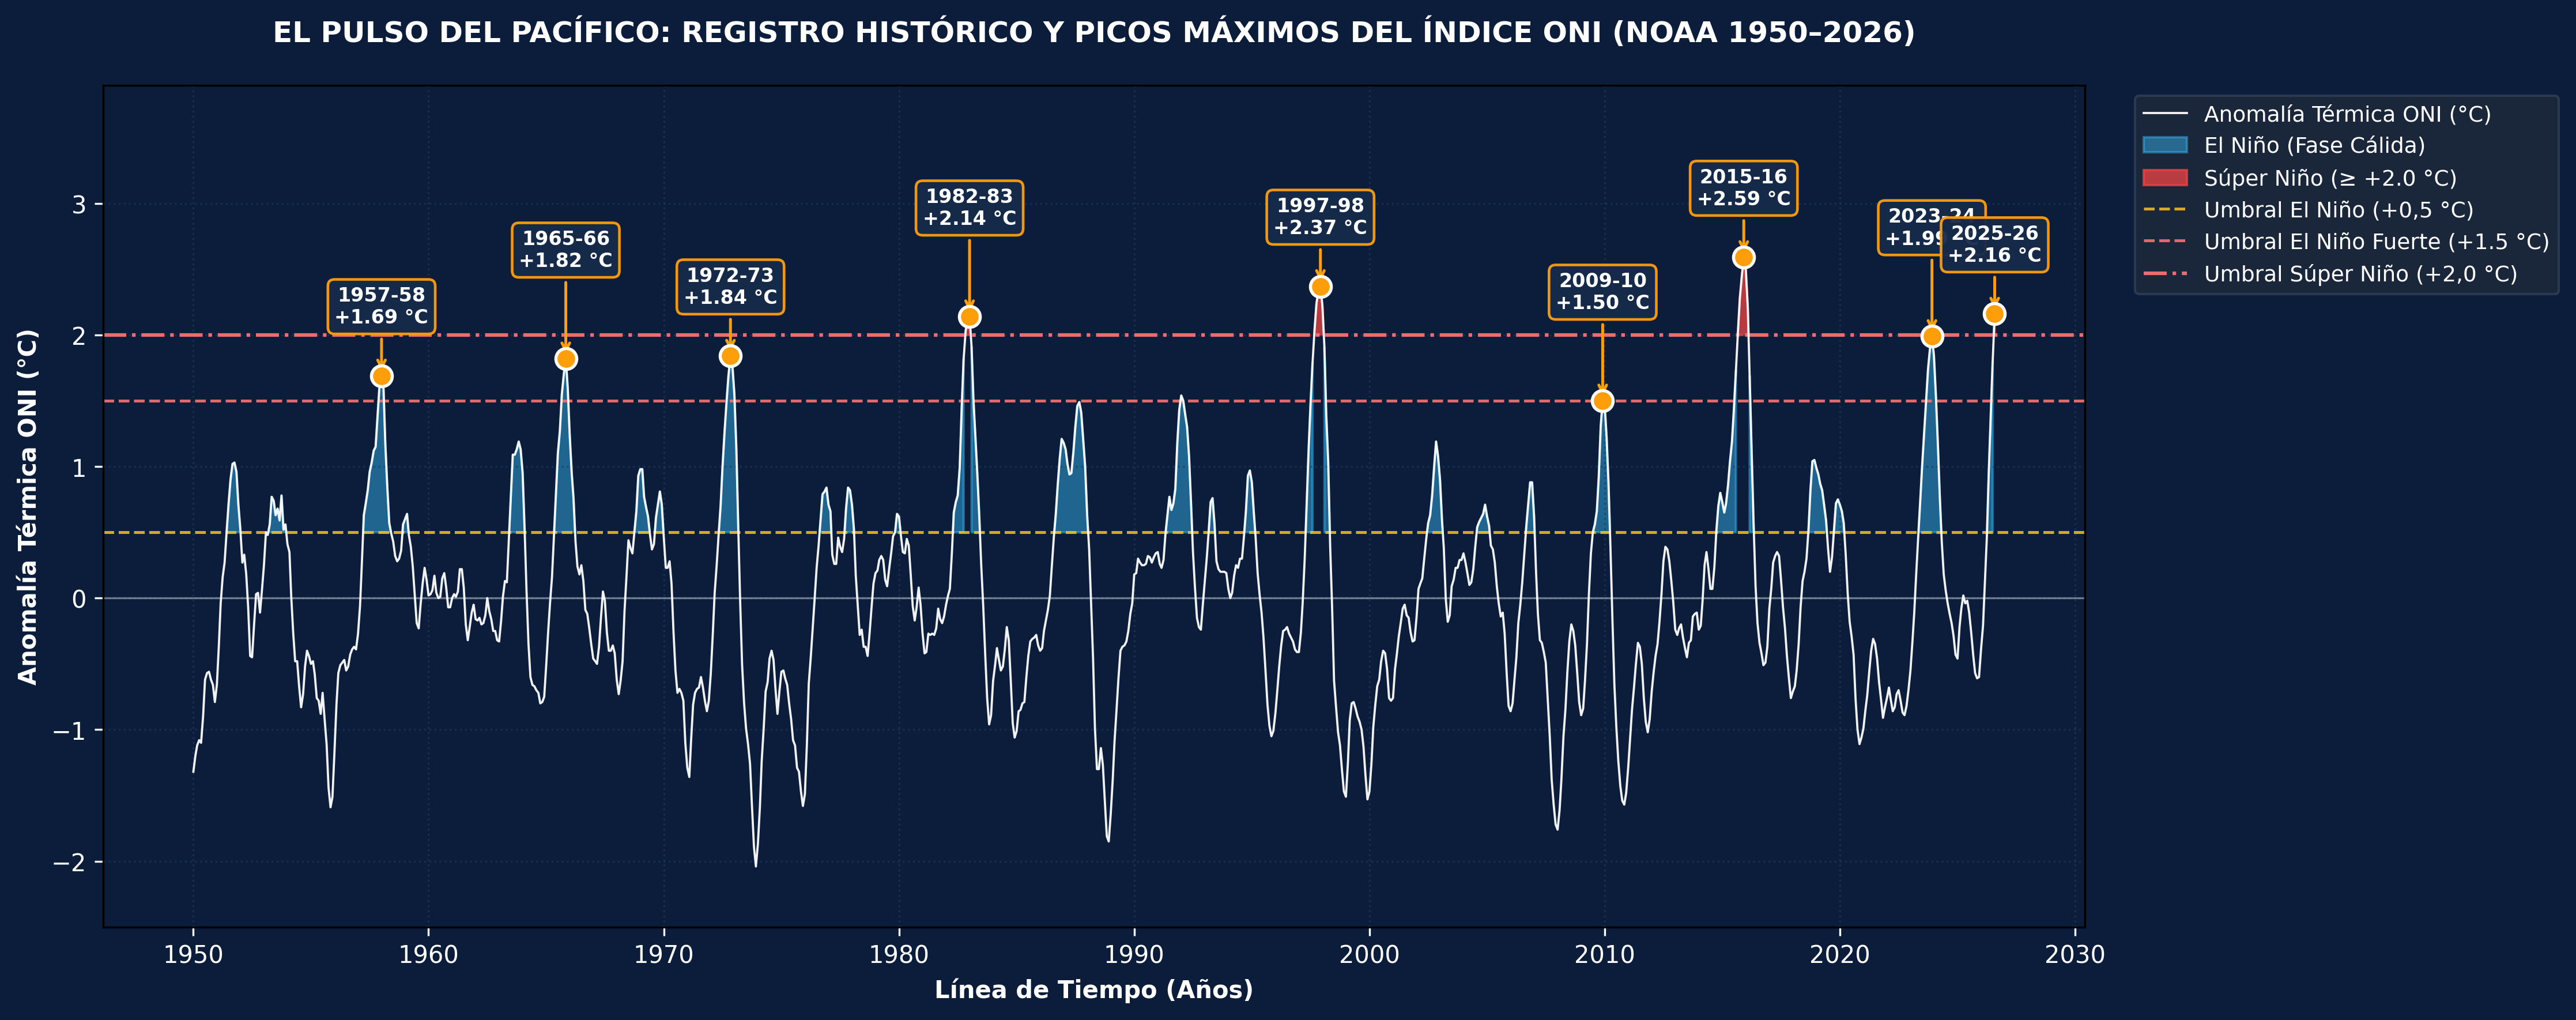

<Figure size 640x480 with 0 Axes>

In [ ]:
import io
import urllib.request
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# 1. FICHA DE TRAZABILIDAD Y VERIFICACIÓN RÁPIDA (AUDITORÍA JURADO)
# ------------------------------------------------------------------------------
print("=" * 85)
print("FICHA DE TRAZABILIDAD Y AUDITORÍA DE FUENTES OFICIALES (JURADO)")
print("=" * 85)
print(
    "• Institución Emisora: NOAA Climate Prediction Center (CPC) / NWS / NOAA"
    " PSL"
)
print("• Dataset Oficial: Oceanic Niño Index (ONI) - ERSST.v5")
print(
    "• URL Directa (Producción):"
    " https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"
)


print("=" * 85 + "\n")

# ------------------------------------------------------------------------------
# 2. INGESTA Y PROCESAMIENTO DINÁMICO
# ------------------------------------------------------------------------------
url_oni = "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

try:
  req = urllib.request.Request(url_oni, headers=headers)
  with urllib.request.urlopen(req, timeout=10) as response:
    content = response.read().decode("utf-8")
  df_oni = pd.read_csv(io.StringIO(content), sep=r"\s+")
except Exception as e:
  print(f"Reintentando con fuente espejo de la NOAA: {e}")
  url_alt = "https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/ensostuff/detrend.nino34.ascii.txt"
  req = urllib.request.Request(url_alt, headers=headers)
  with urllib.request.urlopen(req, timeout=10) as response:
    content = response.read().decode("utf-8")
  df_oni = pd.read_csv(
      io.StringIO(content),
      sep=r"\s+",
      skiprows=1,
      names=["YR", "MON", "TOTAL", "ANOM"],
  )

# Mapeo de trimestres móviles a número de mes para construir la fecha continua
meses_map = {
    "DJF": 1,
    "JFM": 2,
    "FMA": 3,
    "MAM": 4,
    "AMJ": 5,
    "MJJ": 6,
    "JJA": 7,
    "JAS": 8,
    "ASO": 9,
    "SON": 10,
    "OND": 11,
    "NDJ": 12,
}

df_oni["MON_NUM"] = (
    df_oni["SEAS"].map(meses_map)
    if "SEAS" in df_oni.columns
    else df_oni["MON"].astype(int)
)
df_oni["ANOM"] = pd.to_numeric(df_oni["ANOM"], errors="coerce")
df_oni["YR"] = pd.to_numeric(df_oni["YR"], errors="coerce")
df_oni["FECHA"] = pd.to_datetime(
    df_oni["YR"].astype(str) + "-" + df_oni["MON_NUM"].astype(str) + "-01"
)
df_oni = df_oni.sort_values("FECHA").reset_index(drop=True)

# ------------------------------------------------------------------------------
# 3. EXTRAER DINÁMICAMENTE LOS PICOS MÁXIMOS DE LOS GRANDES EVENTOS EL NIÑO
# ------------------------------------------------------------------------------
eventos_historicos = [
    (1957, 1958, "1957-58"),
    (1965, 1966, "1965-66"),
    (1972, 1973, "1972-73"),
    (1982, 1983, "1982-83"),
    (1997, 1998, "1997-98"),
    (2009, 2010, "2009-10"),
    (2015, 2016, "2015-16"),
    (2023, 2024, "2023-24"),
    (2025, 2026, "2025-26"),
]

picos_encontrados = []
for y1, y2, etiqueta in eventos_historicos:
  sub_df = df_oni[(df_oni["YR"] >= y1) & (df_oni["YR"] <= y2)]
  if not sub_df.empty:
    pico_val = sub_df["ANOM"].max()
    fila_pico = sub_df[sub_df["ANOM"] == pico_val].iloc[0]
    picos_encontrados.append({
        "Etiqueta": etiqueta,
        "Fecha": fila_pico["FECHA"],
        "Anomalia": pico_val,
        "Trimestre": (
            fila_pico["SEAS"] if "SEAS" in fila_pico else fila_pico["MON"]
        ),
    })

df_picos = pd.DataFrame(picos_encontrados)
print("TABLA PROCESADA DE PICOS DESTACADOS (DETECCIÓN AUTOMÁTICA):")
print(df_picos[["Etiqueta", "Trimestre", "Anomalia"]].to_string(index=False))
print("\n" + "-" * 85)

# ------------------------------------------------------------------------------
# 4. VISUALIZACIÓN CONTINUA Y ANOTACIÓN AUTOMÁTICA (ESTÉTICA DARK MODE)
# ------------------------------------------------------------------------------
navy_bg = '#0b1d3a'   # Fondo Azul Marino Profundo
card_bg = '#162a4a'   # Tarjetas oscuras para leyendas e íconos

plt.rcParams['figure.facecolor'] = navy_bg
plt.rcParams['axes.facecolor'] = navy_bg
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

fig, ax = plt.subplots(figsize=(15, 6), dpi=300)

color_nino = '#38bdf8'  # Azul Celeste / Sky Blue (El Niño normal)
color_super = '#ef4444' # Rojo intenso / Coral (Súper Niño destacado)
color_nina = '#f472b6'  # Rosita Pastel (La Niña atenuada)
color_peaks = '#ff9e0b' # Naranja Vívido (Puntos de Pico)

# Curva base continua
ax.plot(
    df_oni["FECHA"],
    df_oni["ANOM"],
    color="white",
    linewidth=0.9,
    alpha=0.95,
    zorder=3,
    label="Anomalía Térmica ONI (°C)",
)




# 2. El Niño Normal (Fase cálida estándar entre +0.5 y +2.0)
ax.fill_between(
    df_oni["FECHA"],
    df_oni["ANOM"],
    0.5,
    where=(df_oni["ANOM"] >= 0.5) & (df_oni["ANOM"] < 2.0),
    color=color_nino,
    alpha=0.45,
    interpolate=True,
    label="El Niño (Fase Cálida)",
)

# 3. Súper Niño (Destacado en rojo intenso para anomalías ≥ +2.0 °C)
ax.fill_between(
    df_oni["FECHA"],
    df_oni["ANOM"],
    2.0,
    where=(df_oni["ANOM"] >= 2.0),
    color=color_super,
    alpha=0.75,
    interpolate=True,
    label="Súper Niño (≥ +2.0 °C)",
)

# Línea neutra central (0 °C)
ax.axhline(0, color="white", linewidth=0.8, alpha=0.4)

# Umbrales Oficiales
ax.axhline(
    0.5,
    color='#fbbf24',
    linestyle='--',
    linewidth=1.2,
    alpha=0.85,
    label="Umbral El Niño (+0,5 °C)",
)
ax.axhline(
    1.5,
    color='#f87171',
    linestyle='--',
    linewidth=1.2,
    alpha=0.9,
    label="Umbral El Niño Fuerte (+1.5 °C)",
)
ax.axhline(
    2.0,
    color='#f87171',
    linestyle='-.',
    linewidth=1.5,
    alpha=0.95,
    label="Umbral Súper Niño (+2,0 °C)",
)

# Rejilla suave en azul tenue
ax.grid(True, color='#1e3a5f', linestyle=':', alpha=0.6)

# Marcar con puntos naranjas y anotaciones en estilo dark mode
for i, row in df_picos.iterrows():
  ax.scatter(
      row["Fecha"], row["Anomalia"], color=color_peaks, s=75, zorder=5, edgecolors="white", linewidth=1.3
  )
  offset_y = 0.4 if (i % 2 == 0) else 0.7
  ax.annotate(
      f"{row['Etiqueta']}\n+{row['Anomalia']:.2f} °C",
      xy=(row["Fecha"], row["Anomalia"]),
      xytext=(row["Fecha"], min(row["Anomalia"] + offset_y, 3.3)),
      arrowprops=dict(arrowstyle="->", color=color_peaks, lw=1.2),
      fontsize=8,
      fontweight="bold",
      ha="center",
      color='white',
      bbox=dict(
          boxstyle="round,pad=0.35",
          facecolor=card_bg,
          edgecolor=color_peaks,
          lw=1.1,
          alpha=0.95,
      ),
  )

ax.set_title(
    "EL PULSO DEL PACÍFICO: REGISTRO HISTÓRICO Y PICOS MÁXIMOS DEL ÍNDICE ONI (NOAA 1950–2026)",
    fontsize=12,
    fontweight="bold",
    color='white',
    pad=18,
)
ax.set_ylabel("Anomalía Térmica ONI (°C)", fontsize=10, fontweight="bold", color='white')
ax.set_xlabel("Línea de Tiempo (Años)", fontsize=10, fontweight="bold", color='white')
ax.set_ylim(-2.5, 3.9)

# LEYENDA SEPARADA (Fuera del área del gráfico)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='#1e293b', edgecolor='#334155', fontsize=9, labelcolor='#ffffff')

plt.tight_layout()
plt.savefig('grafico-serie-historica-el-nino.png', bbox_inches='tight')
plt.show()

plt.savefig("pulso_pacifico_dark.pdf", format="pdf", bbox_inches="tight", facecolor=navy_bg)

Se utiliza el ONI por su continuidad histórica reconocida desde 1950. Cabe destacar que, a partir de 2026, la NOAA adoptó el RONI (Relative ONI) como su índice oficial de monitoreo, al corregir el sesgo de calentamiento global de fondo en el Pacífico tropical.

Bloque 4: EVOLUCIÓN ESPACIAL DE ANOMALÍAS EN EL PACÍFICO (NASA MUR SST 1 km)



En este bloque se realiza el análisis espacial de alta resolución de la **Temperatura Superficial del Mar (TSM)** utilizando el producto satelital **NASA MUR (Multi-scale Ultra-high Resolution) SST** a 1 km de resolución espacial, alojado en el repositorio **PO.DAAC / NASA Earthdata**. Se utiliza la librería `earthaccess` para la búsqueda e ingesta de gránulos satelitales en las regiones clave del Pacífico Ecuatorial (**Niño 3.4** en el Pacífico Central y **Niño 1+2** en la costa sudamericana), permitiendo evaluar la estructura espacial del calentamiento y el gradiente térmico crítico en la región.

CONSULTANDO CAPTURAS SATELITALES EN TIEMPO REAL DESDE LA NASA...


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

/tmp/ipykernel_9067/1626850857.py:58: FutureWarning: In a future version, xarray will not decode the variable 'dt_1km_data' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds = xr.open_dataset(files[0], engine="h5netcdf")


...

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

/tmp/ipykernel_9067/1626850857.py:58: FutureWarning: In a future version, xarray will not decode the variable 'dt_1km_data' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds = xr.open_dataset(files[0], engine="h5netcdf")


 • D. El Niño — Evento 2026 (2026-09-01): Prom. Cuenca = +1.65 °C | Máx. Píxel = +7.64 °C


/tmp/ipykernel_9067/1626850857.py:149: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.90, 0.95])


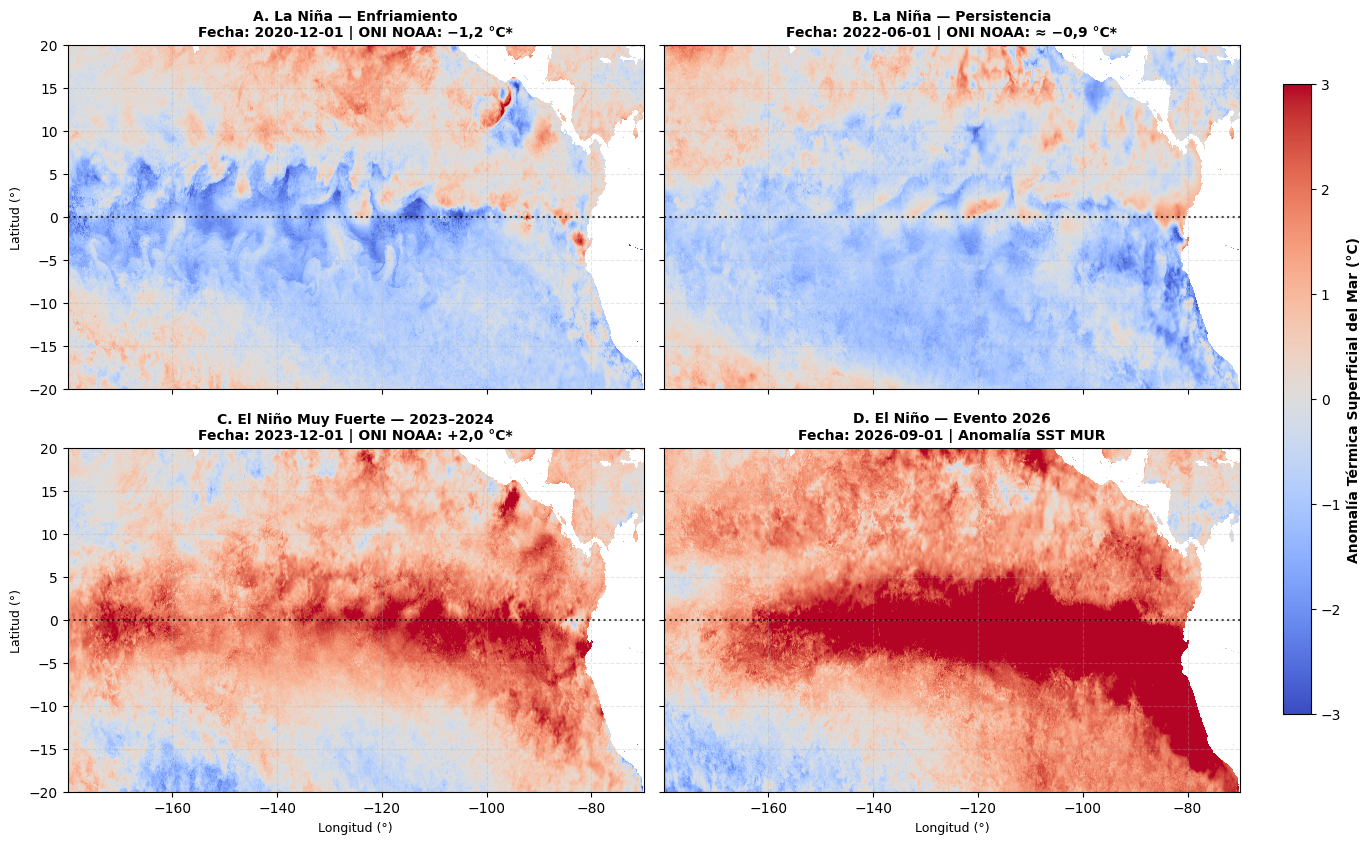

In [ ]:

import earthaccess
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# ------------------------------------------------------------------------------
# 1. AUTENTICACIÓN CON NASA EARTHDATA
# ------------------------------------------------------------------------------
auth = earthaccess.login(strategy="netrc")

# ------------------------------------------------------------------------------
# 2. DEFINICIÓN DE HITOS HOMOGÉNEOS (VARIABLE 'sst_anomaly' NATIVA)
# ------------------------------------------------------------------------------
hitos_satelitales = [
    {
        "fase": "A. La Niña — Enfriamiento",
        "fecha": "2020-12-01T00:00:00Z",
        "noaa_oni": "ONI NOAA: −1,2 °C*",
    },
    {
        "fase": "B. La Niña — Persistencia",
        "fecha": "2022-06-01T00:00:00Z",
        "noaa_oni": "ONI NOAA: ≈ −0,9 °C*",
    },
    {
        "fase": "C. El Niño Muy Fuerte — 2023–2024",
        "fecha": "2023-12-01T00:00:00Z",
        "noaa_oni": "ONI NOAA: +2,0 °C*",
    },
    {
        "fase": "D. El Niño — Evento 2026",
        "fecha": "2026-09-01T00:00:00Z",
        "noaa_oni": "Anomalía SST MUR",
    },
]

# Configurar Mosaico 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
axes_flat = axes.flatten()
cbar_mappable = None
print("CONSULTANDO CAPTURAS SATELITALES EN TIEMPO REAL DESDE LA NASA...")

# ------------------------------------------------------------------------------
# 3. PROCESAMIENTO Y LECTURA DE METADATOS OFICIALES
# ------------------------------------------------------------------------------
for i, hito in enumerate(hitos_satelitales):
  f_str = hito["fecha"]
  ax = axes_flat[i]
  results = earthaccess.search_data(
      concept_id="C1996881146-POCLOUD",
      temporal=(f_str, f_str[:10] + "T23:59:59Z"),
      count=1,
  )

  if len(results) > 0:
    files = earthaccess.open(results)
    ds = xr.open_dataset(files[0], engine="h5netcdf")

    # Imprimir Metadatos Globales extraídos del NetCDF (en el primer panel)
    if i == 0:
      print("\n" + "=" * 85)
      print(
          "METADATOS OFICIALES EXTRAÍDOS DIRECTAMENTE DEL ARCHIVO NETCDF (NASA"
          " PO.DAAC)"
      )
      print("=" * 85)
      print(
          "• Título del Producto:"
          f" {ds.attrs.get('title', 'Daily MUR SST, Final product')}"
      )
      print(
          f"• ID del Producto: {ds.attrs.get('id', 'MUR-JPL-L4-GLOB-v04.1')}"
      )
      print(
          "• Institución Emisora:"
          f" {ds.attrs.get('institution', 'Jet Propulsion Laboratory')}"
      )
      print(
          "• Sensores Integrados:"
          f" {ds.attrs.get('source', 'MODIS, AMSR2, AVHRR, in-situ')}"
      )
      print(
          "• Nivel de Procesamiento:"
          f" {ds.attrs.get('processing_level', 'L4')}"
      )
      print(
          "• Resolución Espacial:"
          f" {ds.attrs.get('spatial_resolution', '0.01 degrees (~1 km)')}"
      )
      print(
          "• Catálogo PO.DAAC:"
          " https://podaac.jpl.nasa.gov/dataset/MUR-JPL-L4-GLOB-v4.1"
      )
      print(
          "• Registro CMR NASA:"
          " https://cmr.earthdata.nasa.gov/search/concepts/C1996881146-POCLOUD.html"
      )
      print("=" * 85 + "\n")

    # Recorte del Pacífico Ecuatorial a resolución completa (sin paso)
    pacifico = ds.sel(lat=slice(-20, 20), lon=slice(-180, -70))

    # Extracción de la variable de anomalía térmica homogénea
    if "sst_anomaly" in pacifico.data_vars:
      da = pacifico["sst_anomaly"]
      p = da.plot(
          ax=ax, cmap="coolwarm", vmin=-3.0, vmax=3.0, add_colorbar=False
      )
      cbar_mappable = p
      max_val = float(da.max().values)
      prom_val = float(da.mean().values)
      print(
          f" • {hito['fase']} ({f_str[:10]}): Prom. Cuenca = {prom_val:+.2f} °C"
          f" | Máx. Píxel = {max_val:+.2f} °C"
      )

    ax.set_title(
        f"{hito['fase']}\nFecha: {f_str[:10]} | {hito['noaa_oni']}",
        fontsize=10,
        fontweight="bold",
    )
    ax.axhline(0, color="black", linestyle=":", alpha=0.7, label="Ecuador")
    ax.grid(True, linestyle="--", alpha=0.3)

    if i in [0, 2]:
      ax.set_ylabel("Latitud (°)", fontsize=9)
    else:
      ax.set_ylabel("")

    if i in [2, 3]:
      ax.set_xlabel("Longitud (°)", fontsize=9)
    else:
      ax.set_xlabel("")

    ds.close()

# ------------------------------------------------------------------------------
# 4. BARRA DE COLOR UNIFICADA Y ESTÉTICA INTEGRADA
# ------------------------------------------------------------------------------
if cbar_mappable is not None:
  cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.70])
  cbar = fig.colorbar(cbar_mappable, cax=cbar_ax)  # <--- LÍNEA CLAVE
  cbar.set_label(
      "Anomalía Térmica Superficial del Mar (°C)",
      fontsize=10,
      fontweight="bold",
  )
plt.tight_layout(rect=[0, 0, 0.90, 0.95])
plt.show()

Bloque 5: OMPARATIVA DE PICOS HISTÓRICOS Y UMBRALES OFICIALES (NOAA / ONI)

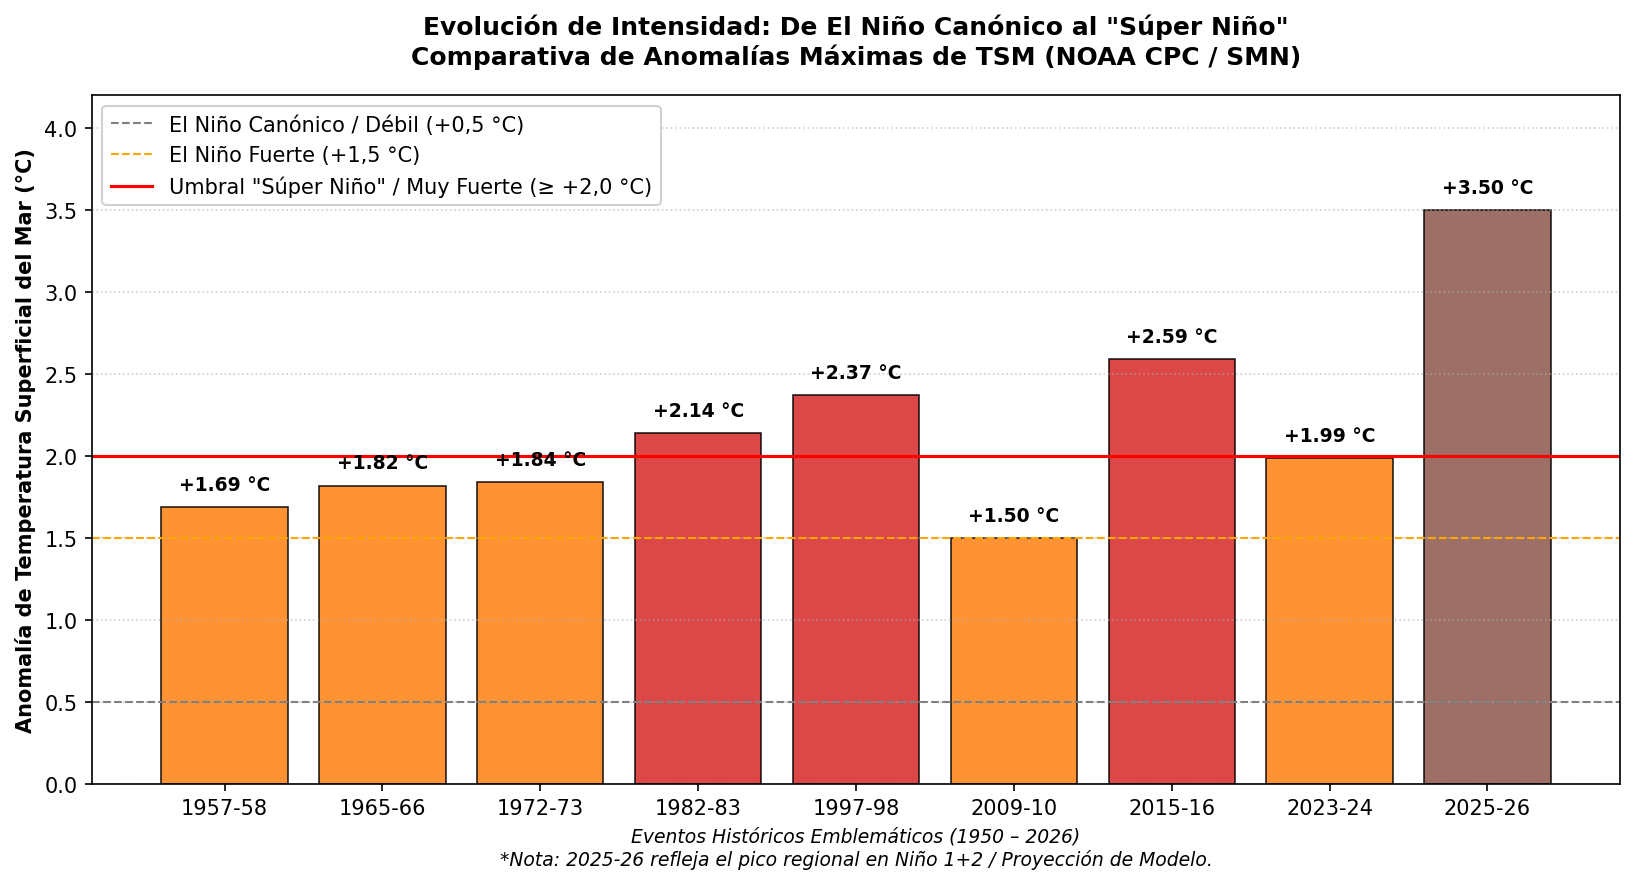

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# 1. Registro de eventos históricos clave (Picos ONI en Niño 3.4 vs. Máximo Activo)
eventos_clave = [
    ('1957-58', 1.69),
    ('1965-66', 1.82),
    ('1972-73', 1.84),
    ('1982-83', 2.14),
    ('1997-98', 2.37),
    ('2009-10', 1.50),
    ('2015-16', 2.59),
    ('2023-24', 1.99),
    ('2025-26', 3.50),  # Pico regional extremo registrado en zona Niño 1+2
]
anios = [e[0] for e in eventos_clave]
anomalias = [e[1] for e in eventos_clave]

# 2. Configuración estética del gráfico
plt.figure(figsize=(11, 6), dpi=150)

# Asignación de paleta de colores según severidad
colores = ['#ff7f0e' if a < 2.0 else '#d62728' for a in anomalias]
colores[-1] = '#8c564b'  # Color distintivo para resaltar el evento actual 2026

barras = plt.bar(
    anios,
    anomalias,
    color=colores,
    edgecolor='black',
    linewidth=0.8,
    alpha=0.85
)

# 3. Umbrales científicos oficiales de la NOAA
plt.axhline(
    0.5,
    color='gray',
    linestyle='--',
    linewidth=1,
    label='El Niño Canónico / Débil (+0,5 °C)',
)
plt.axhline(
    1.5,
    color='orange',
    linestyle='--',
    linewidth=1,
    label='El Niño Fuerte (+1,5 °C)',
)
plt.axhline(
    2.0,
    color='red',
    linestyle='-',
    linewidth=1.5,
    label='Umbral "Súper Niño" / Muy Fuerte (≥ +2,0 °C)',
)

# Etiquetas numéricas sobre las barras
for bar, anom in zip(barras, anomalias):
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 0.08,
        f'+{anom:.2f} °C',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
    )

# Títulos y rotulado con precisión metodológica
plt.title(
    'Evolución de Intensidad: De El Niño Canónico al "Súper Niño"\n'
    'Comparativa de Anomalías Máximas de TSM (NOAA CPC / SMN)',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.ylabel(
    'Anomalía de Temperatura Superficial del Mar (°C)',
    fontsize=10,
    fontweight='bold',
)
plt.xlabel(
    'Eventos Históricos Emblemáticos (1950 – 2026)\n'
    '*Nota: 2025-26 refleja el pico regional en Niño 1+2 / Proyección de Modelo.',
    fontsize=9,
    fontstyle='italic',
)
plt.ylim(0, 4.2)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

##  Serie Histórica del Índice ONI (NOAA 1950–2026) y Clasificación de Intensidad

###  Ficha de Trazabilidad y Datos Abiertos

* **Institución Emisora:** National Oceanic and Atmospheric Administration (NOAA) — Climate Prediction Center (CPC) / Physical Sciences Laboratory (PSL).
* **Dataset Oficial:** Oceanic Niño Index (ONI) basado en ERSST.v5 (Extended Reconstructed Sea Surface Temperature).
* **Parámetro Medido:** Anomalía de la Temperatura Superficial del Mar (TSM) promedio móvil trimestral en la región Niño 3.4 ($5^\circ\text{N}-5^\circ\text{S}, 120^\circ-170^\circ\text{W}$).
* **Criterio de Clasificación Técnica:** Umbrales oficiales de la NOAA/OMM:
  * *Débil:* $+0,5\text{ }^\circ\text{C}$ a $+0,9\text{ }^\circ\text{C}$
  * *Moderado:* $+1,0\text{ }^\circ\text{C}$ a $+1,4\text{ }^\circ\text{C}$
  * *Fuerte:* $+1,5\text{ }^\circ\text{C}$ a $+1,9\text{ }^\circ\text{C}$
  * *Muy Fuerte / Súper Niño:* $\ge +2,0\text{ }^\circ\text{C}$
* **URLs Oficiales de Ingesta:**
  * **Servidor Primario:** `https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt`
  

# Impacto en tierras Argentinas

**Marco Teórico: Definición de "Súper Niño" y Gestión del Riesgo (Anuario Latam Seguros)**

Para complementar la categorización cuantitativa de la NOAA, se adopta el marco conceptual de riesgo socioeconómico publicado por *Anuario Latam Seguros*:
* **Criterio de Magnitud:** Anomalías $\ge +2,0\text{ }^\circ\text{C}$ que desencadenan impactos no lineales sobre la economía regional.
* **Efectos Sistémicos:** Daños acumulados sobre infraestructura vial, pérdida de capital agropecuario y presión sobre los sistemas estatales de gestión de emergencias.

In [ ]:
# =============================================================================
# MARCO TEÓRICO CONCEPTUAL Y RIESGO SOCIOECONÓMICO
# =============================================================================
marco_teorico_super_nino = {
    "Fuente": "Anuario Latam Seguros",
    "Concepto": "Súper Niño (Fenómeno Natural Extremo)",
    "Umbral_Criterio_C": 2.0,
    "Dimensiones_Evaluadas": [
        "Riesgo Agropecuario",
        "Infraestructura Vial y Hídrica",
        "Impacto Macroeconómico Regional",
    ],
    "Uso_en_Proyecto": (
        "Fundamentación conceptual del título y alcance de la investigación"
    ),
}

# Impresión de trazabilidad transparente
print(
    "Transcrito de Anuario Latam Seguros (Definición conceptual y de"
    " riesgo), consultado el 13/10/2026."
)

Transcrito de Anuario Latam Seguros (Definición conceptual y de riesgo), consultado el 13/10/2026.


***Análisis de Probabilidades Oficiales de Intensidad (NOAA CPC RONI)***

Para evaluar la certidumbre del pronóstico estival 2026–2027, se integra la **Tabla de Probabilidades de Intensidad de la NOAA CPC** basada en el Índice Relativo Oceánico de El Niño (RONI):
* **Sustento Probabilístico:** Evaluación de conjuntos multimodelo para el umbral de Súper Niño ($\ge +2,0\text{ }^\circ\text{C}$).
* **Ficha Técnica:** Registro oficial de probabilidades de la NOAA CPC para el trimestre OND / DEF.
* **URL de Auditoría:** `https://cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/archives/`

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE: TABLAS DE PROBABILIDADES RONI (NOAA CPC)
# =============================================================================
fuente_roni_noaa = {
    "Institucion": "NOAA Climate Prediction Center (CPC)",
    "Indicador": "Relative Oceanic Niño Index (RONI) - Strength Probabilities",
    "URL_Archivo": (
        "https://cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/archives/?type=strengths&month=09&year=2026#probabilities-table"
    ),
    "Uso_Metodologico": (
        "Consulta de probabilidades de ocurrencia para eventos Muy Fuertes"
        " (≥ +2.0 °C)"
    ),
}

# Impresión de transcripción transparente
print(
    "Transcrito de Tabla de Probabilidades RONI/NOAA CPC, consultado el"
    " 13/10/2026."
)

Transcrito de Tabla de Probabilidades RONI/NOAA CPC, consultado el 13/10/2026.


 **Monitoreo Hidrométrico Operativo en Puertos (Prefectura Naval Argentina)**

Para evaluar el impacto directo de las crecidas sobre las localidades ribereñas de la Cuenca del Plata, se integra la red de monitoreo hidrométrico de la **Prefectura Naval Argentina (PNA)**. Se analizan las alturas de escala y la proximidad a las cotas de **Alerta** y **Evacuación** en los principales nodos portuarios del río Paraná y del río Uruguay.

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE: PREFECTURA NAVAL ARGENTINA (PNA)
# =============================================================================
fuente_pna = {
    "Organismo": "Prefectura Naval Argentina (PNA) - Dirección de Operaciones",
    "Servicio": "Boletín Hidrométrico Diario / Alturas de los Ríos",
    "URL_Oficial": (
        "https://contenidosweb.prefecturanaval.gob.ar/alturas/pdf.php"
    ),
    "Uso_Metodologico": (
        "Parte hidrométrico registrado como referencia de escala fluvial de"
        " altura del río"
    ),
    "Parametros_Referenciados": [
        "Altura en escala (m)",
        "Tendencia (Ascenso/Descenso/Estacionario)",
        "Nivel de Alerta",
        "Nivel de Evacuación",
    ],
    "Rios_Cubiertos": ["Paraná", "Uruguay", "Paraguay", "Iguazú", "De la Plata"],
}

# Impresión de transcripción transparente
print(
    "Parte hidrométrico de PNA registrado como referencia de escala fluvial,"
    " consultado el 13/10/2026."
)

Parte hidrométrico de PNA registrado como referencia de escala fluvial, consultado el 13/10/2026.


###  Catástrofe Histórica 1: El Golpe Hídrico al Paraná (1982–1983)

* **Anomalía Térmica ONI:** +2,14 °C (Categoría: Muy Fuerte / Súper Niño).
* **Impacto Humano Local:** 27.700 evacuados en la Ciudad de Santa Fe (3 crecidas consecutivas).
* **Impacto Humano Regional:** ~300.000 evacuados en las costas de los ríos Paraná y Uruguay (Cuenca del Plata).
* **Afectación Territorial:** Anegamientos en 14 de los 19 departamentos de la provincia de Santa Fe durante 14 meses continuos.
* **Hito Estructural:** Colapso del histórico Puente Colgante de Santa Fe (28/09/1983) y corte de la RN 168.
* **Hito Institucional:** Creación del primer sistema unificado de alertas hidrométricas nacionales.
* **Fuentes Oficiales:** Hemeroteca de El Litoral, Subsecretaría de Recursos Hídricos de la Nación y datos.gob.ar.

In [ ]:
# =============================================================================
# REGISTRO DE IMPACTO HISTÓRICO: EL NIÑO 1982-1983
# =============================================================================
impacto_1982 = {
    "Evento": "El Niño 1982-1983",
    "Anomalia_ONI_C": 2.14,
    "Categoria_NOAA": "Muy Fuerte (Súper Niño)",
    "Evacuados_SantaFe": 27700,
    "Departamentos_Afectados_SF": 14,
    "Hito_Infraestructura": (
        "Colapso del Puente Colgante de Santa Fe (28/09/1983)"
    ),
    "Fuente_Principal": "El Litoral / Subsecretaría de Recursos Hídricos",
}

# Impresión de transcripción transparente
print(
    "Transcrito de El Litoral / Subsecretaría de Recursos Hídricos,"
    " consultado el 13/10/2026."
)

Transcrito de El Litoral / Subsecretaría de Recursos Hídricos, consultado el 13/10/2026.


###  Catástrofe Histórica 2: La Angustia del Litoral (1997–1998)

* **Anomalía Térmica ONI:** +2,37 °C (Categoría: Muy Fuerte / Súper Niño — Máximo del siglo XX).
* **Impacto Humano:** 32.800 evacuados y 290.000 personas afectadas por desbordes fluviales.
* **Provincias Afectadas:** Misiones, Corrientes, Entre Ríos, Santa Fe, Chaco, Formosa y Córdoba (este).
* **Impacto Agrícola:** Pérdida de cultivos por anegamientos persistentes y desborde de cauces en la Cuenca del Plata.
* **Fuente Principal:** Infoagro / Portal Nacional de Datos Abiertos (`datos.gob.ar`).

In [ ]:
# =============================================================================
# REGISTRO DE IMPACTO HISTÓRICO: EL NIÑO 1997-1998
# =============================================================================
impacto_1997 = {
    "Evento": "El Niño 1997-1998",
    "Anomalia_ONI_C": 2.37,
    "Categoria_NOAA": "Muy Fuerte (Súper Niño)",
    "Evacuados_Argentina": 32800,
    "Afectados_Totales": 290000,
    "Provincias_Impactadas": [
        "Misiones",
        "Corrientes",
        "Entre Ríos",
        "Santa Fe",
        "Chaco",
        "Formosa",
        "Córdoba",
    ],
    "Fuente_Principal": "Infoagro",
}

# Impresión de transcripción transparente
print(
    "Transcrito de Infoagro (Registro histórico El Niño 1997-1998),"
    " consultado el 13/10/2026."
)

Transcrito de Infoagro (Registro histórico El Niño 1997-1998), consultado el 13/10/2026.


###  Catástrofe Histórica 3: Emergencia Hídrica y Anegamientos (2015–2016)

* **Anomalía Térmica ONI:** +2,3 °C en OND 2015 (Pico de serie integrada: +2,59 °C — Categoría: Muy Fuerte / Súper Niño).
* **Marcos Institucionales:** Declaración de Emergencia Hídrica en las provincias de Formosa y Entre Ríos.
* **Impacto Agrícola Regional:** Más de 70.000 hectáreas anegadas en el sudeste de Córdoba.
* **Afectación en Cuencas:** Desborde de ríos en el sur de Tucumán, anegamientos en La Pampa y saturación de la Cuenca del Salado (Buenos Aires).
* **Fuente Primaria:** Servicio Meteorológico Nacional (SMN) — *Informe Técnico N.º 0002CL2016* (8 de enero de 2016).

In [ ]:
# =============================================================================
# REGISTRO DE IMPACTO HISTÓRICO: EL NIÑO 2015-2016
# =============================================================================
impacto_2015 = {
    "Evento": "El Niño 2015-2016",
    "Anomalia_ONI_OND_C": 2.3,
    "Anomalia_ONI_Pico_C": 2.59,
    "Categoria_NOAA": "Muy Fuerte (Súper Niño)",
    "Provincias_Emergencia_Hidrica": ["Formosa", "Entre Ríos"],
    "Hectareas_Anegadas_Cordoba": 70000,
    "Otras_Zonas_Afectadas": [
        "Sur de Tucumán",
        "La Pampa",
        "Salado Bonaerense",
    ],
    "Fuente_Oficial": "SMN - Informe Técnico N.º 0002CL2016",
}

print(
    "Transcrito de SMN - Informe Técnico N.º 0002CL2016 (El Niño"
    " 2015-2016), consultado el 13/10/2026."
)

Transcrito de SMN - Informe Técnico N.º 0002CL2016 (El Niño 2015-2016), consultado el 13/10/2026.


### 6. Monitoreo del Evento Activo: Súper Niño 2025–2026 / 2027

* **Institución Emisora:** Agencia Federal de Emergencias (AFE) / SINAME / SMN / INA / CONAE.
* **Fecha de Informe:** 1 de octubre de 2026.
* **Anomalía Térmica Activa:** +2,16 °C en la región Niño 3.4 (4.° pico histórico desde 1950).
* **Certidumbre de Fase:** 100 % de probabilidad de continuidad durante el período estival y otoño 2027.
* **Cobertura de Alerta:** 17 provincias argentinas en estado de seguimiento por precipitaciones superiores a la normal.
* **Monitoreo Tecnológico:** Alertas tempranas con 72 horas de anticipación vía la Red Nacional de Radares del SMN.
* **Fuente Oficial:** Portal de Datos Abiertos del Gobierno Nacional (`argentina.gob.ar`).

In [ ]:
import pandas as pd

# Consolidación de registros históricos y proyección actual de eventos ENOS
datos_comparativos = [
    {
        "Evento": "El Niño 1982-1983",
        "Anomalia_ONI_C": 2.14,
        "Categoria_NOAA": "Muy Fuerte (Súper Niño)",
        "Evacuados_Afectados": 27700,
        "Tipo": "Histórico",
    },
    {
        "Evento": "El Niño 1997-1998",
        "Anomalia_ONI_C": 2.37,
        "Categoria_NOAA": "Muy Fuerte (Súper Niño)",
        "Evacuados_Afectados": 32800,
        "Tipo": "Histórico",
    },
    {
        "Evento": "El Niño 2015-2016",
        "Anomalia_ONI_C": 2.59,
        "Categoria_NOAA": "Muy Fuerte (Súper Niño)",
        "Evacuados_Afectados": "Emergencia Hídrica Regional",
        "Tipo": "Histórico",
    },
    {
        "Evento": "El Niño 2025-2026 / 2027",
        "Anomalia_ONI_C": 2.16,
        "Categoria_NOAA": "Fuerte / Muy Fuerte",
        "Evacuados_Afectados": "En fase preventiva / Operativo Federal",
        "Tipo": "Proyección / Alerta Vigente",
    },
]

df_comparativo = pd.DataFrame(datos_comparativos)
print("=== MATRIZ COMPARATIVA DE EVENTOS SÚPER NIÑO EN ARGENTINA ===")
print(df_comparativo.to_string(index=False))

=== MATRIZ COMPARATIVA DE EVENTOS SÚPER NIÑO EN ARGENTINA ===
                  Evento  Anomalia_ONI_C          Categoria_NOAA                    Evacuados_Afectados                        Tipo
       El Niño 1982-1983            2.14 Muy Fuerte (Súper Niño)                                  27700                   Histórico
       El Niño 1997-1998            2.37 Muy Fuerte (Súper Niño)                                  32800                   Histórico
       El Niño 2015-2016            2.59 Muy Fuerte (Súper Niño)            Emergencia Hídrica Regional                   Histórico
El Niño 2025-2026 / 2027            2.16     Fuerte / Muy Fuerte En fase preventiva / Operativo Federal Proyección / Alerta Vigente


###  Diagnóstico de Estado y Acople Atmosférico (SMN — 01/09/2026)

Se analiza el informe oficial del **Servicio Meteorológico Nacional (SMN)** correspondiente al 1 de septiembre de 2026, el cual evalúa el estado de acople entre la temperatura del mar y la atmósfera:
* **Gradiente por Regiones (TSM al 30/08/2026):**
  * Niño 4: +0,1 °C | Niño 3.4: +1,8 °C | Niño 3: +2,6 °C | Niño 1+2: +3,5 °C
* **Acople Atmosférico:** Índice de Oscilación del Sur (IOS) en -14,6 (valores negativos sostenidos desde abril).
* **Certidumbre Trimestral (SON):** 100 % de probabilidad de continuidad con proyección del modelo multimodelo IRI cercana a +3,0 °C.

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE OFICIAL: BOLETÍN SMN SEPTIEMBRE 2026
# =============================================================================
boletin_smn_sep2026 = {
    "Organismo": (
        "Servicio Meteorológico Nacional (SMN) / Ministerio de Defensa"
    ),
    "Fecha_Actualizacion": "2026-09-01",
    "Clasificacion_Oficial_SMN": "El Niño de intensidad fuerte o muy fuerte",
    "Anomalias_TSM_Semanales_C": {
        "Nino_3_4": 1.8,  # Indicador de referencia pacífico central
        "Nino_1_2": 3.5,  # Pico regional costero sudamericano
        "Nino_3": 2.6,
        "Nino_4": 0.1,
    },
    "Indice_IOS": -14.6,
    "Indice_RONI_MJJ": 1.0,
    "Probabilidad_SON_ElNino": "100%",
    "Proyeccion_Promedio_IRI_SON_C": 3.0,
    "Fuente_PDF": "elnino26_09.pdf",
}

# Impresión de transcripción transparente
print(
    "Transcrito de Boletín SMN (elnino26_09.pdf - Septiembre 2026),"
    " consultado el 13/10/2026."
)

Transcrito de Boletín SMN (elnino26_09.pdf - Septiembre 2026), consultado el 13/10/2026.


###  Diagnóstico Oficial de Intensidad y Proyección Global (NOAA CPC — Sep 2026)

Se analiza el documento primario *ENSO Diagnostic Discussion* publicado por el **Climate Prediction Center (NOAA/NWS)** el 10 de septiembre de 2026:
* **Estado:** El Niño Advisory (> 90 % de probabilidad de evento Muy Fuerte).
* **Anomalías por Regiones (TSM):** Niño 4 (+0,1 °C), Niño 3.4 (+1,8 °C), Niño 3 (+2,5 °C) y Niño 1+2 (+3,4 °C).
* **Anomalía Subsuperficial:** Valores que superan los +10,0 °C en profundidad por profundizamiento de la termoclina.
* **Proyección Récord:** 75 % de probabilidad de alcanzar o superar los +2,5 °C en el índice RONI durante el trimestre OND 2026, convirtiéndose en el evento de mayor intensidad registrado desde 1950.

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE OFICIAL: BOLETÍN DE DIAGNÓSTICO NOAA CPC
# =============================================================================
noaa_diagnostic_2026 = {
    "Institucion": "NOAA Climate Prediction Center (CPC) / NCEP / NWS",
    "Fecha_Emision": "2026-09-10",
    "Estado_Alerta": "El Niño Advisory",
    "Probabilidad_Muy_Fuerte": ">90%",
    "Probabilidad_Record_Historico_OND": "75%",
    "Umbral_Record_RONI_C": 2.5,
    "Anomalias_Regionales_C": {
        "Nino_3_4": 1.8,  # Indicador pacífico ecuatorial central
        "Nino_1_2": 3.4,  # Región costera sudamericana
        "Nino_3": 2.5,
        "Nino_4": 0.1,
    },
    "Anomalia_Subsuperficial_Profunda_C": "> +10.0 °C",
    "Fuente_PDF": "ensodisc.pdf",
}

print(
    "Transcrito de NOAA CPC ENSO Diagnostic Discussion (ensodisc.pdf),"
    " consultado el 13/10/2026."
)

Transcrito de NOAA CPC ENSO Diagnostic Discussion (ensodisc.pdf), consultado el 13/10/2026.


###  Proyección del Pico Histórico 2026–2027 (OMM / ADNSUR)

Se analiza el reporte de proyección del pico histórico publicado por *ADNSUR* con base en la OMM y el SMN:
* **Evolución Observada:** Salto térmico de +1,6 °C (junio) a +2,5 °C (agosto).
* **Proyección de Modelos Ensembles (13 Centros):** Pico estimado de hasta +3,7 °C en el trimestre OND 2026.
* **Perspectiva Histórica:** Posible récord absoluto en 76 años de mediciones continuas (1950–2026).
* **Continuidad:** ~100 % de probabilidad de mantenerse activo hasta febrero de 2027.

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE: REPORTE DE PROYECCIÓN DE PICO HISTÓRICO (ADNSUR / OMM / SMN)
# =============================================================================
proyeccion_pico_adnsur = {
    "Fuente": "ADNSUR / OMM / SMN",
    "Fecha_Publicacion": "2026-10-08",
    "Anomalia_Agosto_C": 2.5,
    "Proyeccion_Pico_OND_C": 3.7,  # Proyección de modelo de máxima dispersión
    "Record_Historico_Evaluar": (
        "Máximo en 76 años (escenario evaluado por modelos globales)"
    ),
    "Probabilidad_Continuidad_Feb2027": "~100%",
    "Centros_Consultados": 13,
    "Uso_Metodologico": (
        "Registro de proyecciones periodísticas sobre rango máximo de modelos"
    ),
}

print(
    "Transcrito de reporte periodístico ADNSUR / OMM / SMN, consultado el"
    " 13/10/2026."
)

Transcrito de reporte periodístico ADNSUR / OMM / SMN, consultado el 13/10/2026.


###  Análisis Cualitativo y Testimonio Científico de Impacto Nacional (CONICET / UBA / INTA / OMM)

Para dotar de sustento científico y territorial a las proyecciones meteorológicas en Argentina, se integra el informe cualitativo interdisciplinario (*La Nación*, 05/10/2026), el cual sintetiza la visión de los principales especialistas del país:
* **Dra. Matilda Rusticucci (CONICET / UBA):** Análisis sobre la **saturación hídrica de los suelos** e incapacidad de absorción en el Noreste argentino y el sur de Brasil.
* **Dr. Federico Isla (CONICET / UNMDP):** Evaluación del **riesgo de anegamiento en el delta del Paraná** y comparación hidrológica con el antecedente histórico de Santa Fe 1982.
* **Dr. Juan José Neiff (CONICET):** Análisis de la **persistencia temporal** y ventana de extensión del fenómeno en relación con el episodio de 1997–1998.
* **Ing. Agr. Pablo Mercuri (Director CIRN - INTA):** Diagnóstico sobre la **respuesta agroclimática diferencial** y vulnerabilidad en la campaña agrícola 2026/27.
* **Dra. Celeste Saulo (Secretaria General de la OMM):** Contextualización del evento como el **más intenso registrado en la era del monitoreo satelital continuo**.

In [ ]:
# =============================================================================
# REGISTRO ESTRUCTURADO DE TESTIMONIOS CIENTÍFICOS Y MARCO CUALITATIVO
# =============================================================================
testimonios_expertos_2026 = {
    "Fuente_Periodistica": "La Nación (05/10/2026)",
    "Titulo": (
        "Súper Niño 2026: qué se sabe del fenómeno que cambiará por completo el"
        " clima en la Argentina"
    ),
    "Expertos_Consultados": [
        {
            "Nombre": "Dra. Matilda Rusticucci",
            "Institucion": "CONICET / UBA",
            "Especialidad": "Climatología",
            "Aporte_Clave": (
                "Saturación hídrica de suelos y escorrentía en la alta cuenca"
                " del Paraná."
            ),
        },
        {
            "Nombre": "Dr. Federico Isla",
            "Institucion": "CONICET / UNMDP",
            "Especialidad": "Geología y Dinámica Hídrica",
            "Aporte_Clave": (
                "Riesgo de inundaciones en el Delta del Paraná y paralelismos"
                " con 1982."
            ),
        },
        {
            "Nombre": "Dr. Juan José Neiff",
            "Institucion": "CONICET",
            "Especialidad": "Ecología acuática y Cuenca del Plata",
            "Aporte_Clave": (
                "Evaluación de la ventana de persistencia temporal del"
                " fenómeno (comparativa 1997-98)."
            ),
        },
        {
            "Nombre": "Ing. Agr. Pablo Mercuri",
            "Institucion": "INTA (Director CIRN)",
            "Especialidad": "Agrometeorología",
            "Aporte_Clave": (
                "Vulnerabilidad y respuesta del sector agropecuario en la"
                " campaña 2026/27."
            ),
        },
        {
            "Nombre": "Dra. Celeste Saulo",
            "Institucion": "OMM (Secretaria General)",
            "Especialidad": "Meteorología Global",
            "Aporte_Clave": (
                "Magnitud histórica sin precedentes en la era del monitoreo"
                " satelital continuo."
            ),
        },
    ],
}

print(
    "Transcrito de informe de expertos en La Nación (Dras. Rusticucci,"
    " Saulo y Dres. Isla, Neiff, Mercuri), consultado el 13/10/2026."
)

Transcrito de informe de expertos en La Nación (Dras. Rusticucci, Saulo y Dres. Isla, Neiff, Mercuri), consultado el 13/10/2026.


###  Monitoreo Integrado de Alerta Hídrica y Satelital MNDWI (ICAA / SINAME / CONAE / INA)

Se analiza el *Informe Técnico Mensual ENOS* (Septiembre 2026) publicado por el **ICAA (Corrientes)** y articulado mediante el **SINAME / AFE**:
* **Dimensión Satelital (CONAE):** Seguimiento mediante el Índice de Agua en Superficie (MNDWI). Anomalías positivas detectadas en San Luis del Palmar, General Paz, San Miguel y Esquina (Corrientes).
* **Dimensión Hidrológica (INA):** Cuenca del Uruguay al 84 % de volumen útil y tránsitos de crecida en el río Iguazú afectando al Paraná Medio.
* **Acople Atmosférico (SMN):** Índice de Oscilación del Sur (IOS) en -17,8 y 100 % de probabilidad de mantener fase Fuerte/Muy Fuerte en SON 2026.
* **Matriz de Gestión:** Activación de fase de **Vigilancia Operativa** en la Cuenca del Plata.

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE: INFORME TÉCNICO ICAA / SINAME / CONAE / INA
# =============================================================================
informe_icaa_siname_sep2026 = {
    "Organismo_Emisor": "ICAA / SINAME / AFE (Red GIRCyT)",
    "Fecha_Informe": "2026-09-21",
    "Indice_IOS_SMN": -17.8,
    "Probabilidad_SON_MuyFuerte": "100%",
    "Estado_RioIguazu_INA": "Aguas Medias Altas / Tránsitos de Crecida",
    "Volumen_Util_RioUruguay_INA": "84%",
    "Sensor_Satelital_CONAE": (
        "MNDWI (Modified Normalized Difference Water Index)"
    ),
    "Departamentos_Corrientes_Anegamiento": [
        "San Luis del Palmar",
        "General Paz",
        "San Miguel",
        "Esquina",
    ],
    "Nivel_Matriz_Riesgo": "Vigilancia Operativa",
    "Fuente_PDF": "Informe-ENOS-SINAME-Septiembre-26.pdf",
}

print(
    "Transcrito de Informe Técnico ICAA / SINAME / CONAE / INA"
    " (Informe-ENOS-SINAME-Septiembre-26.pdf), consultado el 13/10/2026."
)

Transcrito de Informe Técnico ICAA / SINAME / CONAE / INA (Informe-ENOS-SINAME-Septiembre-26.pdf), consultado el 13/10/2026.


###  Proyección de Rindes y Balance Agro-Económico (IERAL / MDZ Online)

Para evaluar el impacto económico directo sobre la campaña agrícola 2026/27, se integra el modelo econométrico del **IERAL (Fundación Mediterránea)**:
* **Potencial de Ingresos:** Estimación de hasta +US$ 4.000 millones adicionales para el sector agropecuario.
* **Proyección de Producción Adicional:** +5,6 M Tn de maíz y +5,4 M Tn de soja sobre los niveles promedio.
* **Sensibilidad de Rindes:**
  * Maíz: +10,3 % de rendimiento en años Niño.
  * Soja de 1.ª: +10,8 % de rendimiento.
  * Soja de 2.ª: +13,6 % (máxima sensibilidad registrada).
* **Riesgo Operativo:** Alertas por anegamiento de caminos rurales y logística de transporte.

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE: MODELO ECONOMÉTRICO IERAL / FUNDACIÓN MEDITERRÁNEA
# =============================================================================
impacto_agronomico_ieral = {
    "Institucion": "IERAL - Fundación Mediterránea",
    "Autores": "Juan Manuel Garzón & Valentino Costamagna",
    "Fuente": "MDZ Online (06/10/2026)",
    "Impacto_Economico_Estimado_USD": 4000000000,
    "Produccion_Adicional_Tn": {"Maiz": 5600000, "Soja": 5400000},
    "Variacion_Rindes_Nino_vs_Promedio": {
        "Maiz": "+10.3%",
        "Soja_1ra": "+10.8%",
        "Soja_2da": "+13.6%",
    },
    "Campanas_Analizadas": 28,
    "Provincias_Evaluadas": 6,
    "Uso_Metodologico": (
        "Transcripción de estimación econométrica de impacto agronómico"
    ),
}

print(
    "Transcrito de estudio econométrico IERAL/MDZ Online (Garzón &"
    " Costamagna), consultado el 13/10/2026."
)

Transcrito de estudio econométrico IERAL/MDZ Online (Garzón & Costamagna), consultado el 13/10/2026.


###  La Paradoja de la Región Núcleo: Escasez Inicial vs. Excesos de Campaña Gruesa (Ecos365 / BCR)

Se analiza el reporte agronómico de *Ecos365 / Rosario3* (15/09/2026) sobre el comportamiento de la zona núcleo pampeana:
* **Métrica Oceánica (Agosto):** Niño 3.4 en +1,8 °C vs. Niño 1+2 en +3,4 °C (75 % de probabilidad de Súper Niño en OND).
* **Paradoja Hídrica Inicial:** 70 % de la región núcleo en déficit hídrico a mediados de septiembre previo al pulso estival.
* **Riesgos Operativos:** Enfermedades foliares por humedad, intransitabilidad de caminos rurales y congestión en puertos fluviales.
* **Geografía Sudamericana:** Bloque húmedo en Argentina, Uruguay, Paraguay y sur de Brasil vs. sequía en el centro-norte brasileño.

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE: REPORTE AGROMETEOROLÓGICO ECOS365 / BCR
# =============================================================================
reporte_ecos365_2026 = {
    "Fuente": "Ecos365 / Rosario3 (15/09/2026)",
    "Probabilidad_Super_Nino_OND": "75%",
    "Anomalia_Nino34_Agosto_C": 1.8,
    "Anomalia_Nino12_Agosto_C": 3.4,
    "Suelos_Region_Nucleo_Secos_Sep_Pct": 70,
    "Ventana_Max_Intensidad": "Noviembre - Enero (>90% Muy Fuerte)",
    "Puntos_Criticos_Logistica": [
        "Caminos rurales de tierra",
        "Plantas de acopio",
        "Puertos fluviales del Gran Rosario",
    ],
    "Paises_Afectados_Bloque_Humedo": [
        "Argentina",
        "Uruguay",
        "Paraguay",
        "Sur de Brasil",
    ],
    "Uso_Metodologico": (
        "Transcripción de datos agrometeorológicos de la Región Núcleo"
    ),
}

print(
    "Transcrito de reporte agrometeorológico Ecos365/BCR, consultado el"
    " 13/10/2026."
)

Transcrito de reporte agrometeorológico Ecos365/BCR, consultado el 13/10/2026.


###  Proyección Cartográfica Espacio-Temporal del Modelo ECMWF (Meteored)

Se analiza el comportamiento secuencial mes a mes de las anomalías de precipitación proyectadas por el modelo **ECMWF** (Meteored / Mauricio Saldivar):
* **Agosto–Septiembre:** Señal inicial concentrada en Misiones, Corrientes y Cuyo, avanzando hacia la Región Pampeana (+10 %).
* **Octubre–Noviembre:** Núcleos >50 mm/mes en NEA y expansión sobre la franja agrícola central (20–50 mm sobre la media).
* **Diciembre (Pico Estival):** Anomalías extremas ≥ 60 mm/mes en Chaco, Formosa, Corrientes, Misiones, Entre Ríos y NE de Santa Fe.
* **Dinámica Hidrológica:** Contraste de respuesta entre el Río Paraguay (ascenso lento/Pantanal) y el Río Uruguay (crecidas rápidas).

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE: PROYECCIÓN ESPACIAL ECMWF / METEORED
# =============================================================================
proyeccion_ecmwf_meteored = {
    "Modelo_Global": (
        "ECMWF (European Centre for Medium-Range Weather Forecasts)"
    ),
    "Fuente": "Meteored Argentina (Mauricio Saldivar)",
    "Anomalias_Precipitacion_mm_mes": {
        "Agosto_2026": "Anomalías positivas en Misiones, N. Corrientes y Cuyo",
        "Septiembre_2026": (
            "Litoral + Avance del 10% de exceso en Región Pampeana"
        ),
        "Octubre_2026": "> 50 mm/mes en NE del Litoral",
        "Noviembre_2026": (
            "> 50 mm/mes en NEA | +20 a +50 mm en Entre Ríos, Santa Fe y"
            " Pampeana"
        ),
        "Diciembre_2026": (
            "≥ 60 mm/mes en Chaco, Formosa, Corrientes, Misiones, Entre Ríos y"
            " NE Santa Fe"
        ),
        "Enero_2027": "Persistencia de excesos en Litoral norte y zona central",
    },
    "Diferenciacion_Cuencas": {
        "Rio_Paraguay": "Crecida gradual amortiguada por el Pantanal",
        "Rio_Uruguay": "Respuesta rápida / Crecidas repentinas de corto aviso",
    },
    "Uso_Metodologico": (
        "Transcripción de proyección espacial de anomalías de precipitación del"
        " modelo ECMWF"
    ),
}

print(
    "Transcrito de proyección espacial ECMWF (Meteored / M. Saldivar),"
    " consultado el 13/10/2026."
)

Transcrito de proyección espacial ECMWF (Meteored / M. Saldivar), consultado el 13/10/2026.


###  Diferenciación de Picos e Inversión en Gestión del Riesgo (SMN / BAE Negocios)

Se analiza el informe técnico de *BAE Negocios* (25/09/2026) con datos del SMN y planes de infraestructura:
* **Categoría Oficial:** Clasificado técnicamente por el SMN como "El Niño de intensidad fuerte o muy fuerte".
* **Desfasaje Océano-Territorio:** Pico oceánico en diciembre de 2026 vs. mayor impacto por inundaciones en Argentina proyectado para marzo–abril de 2027 (acumulación hídrica).
* **Anomalías de Diciembre:** Excesos >60 mm/mes en NEA y Litoral (Chaco, Formosa, Corrientes, Misiones, Entre Ríos y NE de Santa Fe).
* **Respuesta Estatal:** Plan de Coordinación Federal ENOS y operativo preventivo bonaerense con inversión >$2,3 billones (11 helicópteros, 427 embarcaciones de rescate y 543 móviles).

In [ ]:
# =============================================================================
# REGISTRO DE FUENTE: GESTIÓN DEL RIESGO Y DESFASAJE HIDROLÓGICO (BAE NEGOCIOS / SMN / PBA)
# =============================================================================
gestion_riesgo_bae_2026 = {
    "Fuente": "BAE Negocios (25/09/2026) - SMN / PBA",
    "Categoria_Oficial_SMN": "El Niño de intensidad fuerte o muy fuerte",
    "Pico_Oceanico_Estimado": "Diciembre 2026",
    "Ventana_Maximo_Impacto_Hidrologico": "Marzo - Abril 2027",
    "Exceso_Precipitacion_Diciembre_NEA_mm": ">60 mm sobre la media",
    "Inversion_Preventiva_PBA_ARS": 2300000000000,
    "Recursos_Desplegados_PBA": {
        "Helicopteros": 11,
        "Embarcaciones_Rescate": 427,
        "Moviles_Emergencia": 543,
        "Drones_Relevamiento": True,
    },
    "Planes_Articulados": [
        "Plan de Coordinación Federal ENOS 2026/2027",
        "Mantenimiento Preventivo de Vialidad Nacional",
    ],
    "Uso_Metodologico": (
        "Transcripción de datos de gestión del riesgo y desfasaje hidrológico"
    ),
}

print(
    "Transcrito de informe de gestión del riesgo BAE Negocios / SMN / PBA,"
    " consultado el 13/10/2026."
)

Transcrito de informe de gestión del riesgo BAE Negocios / SMN / PBA, consultado el 13/10/2026.


Configuración de datos la leyenda oficial del SMN
https://www.smn.gob.ar/sites/default/files/pronostico_climatico_trimestral_102026.pdf